[manuel] it=0050 perte=3.559640
[manuel] it=0100 perte=0.533011
[manuel] it=0150 perte=0.088483
[manuel] it=0200 perte=0.022088
[manuel] it=0250 perte=0.012014
[manuel] it=0300 perte=0.010462
[manuel] it=0350 perte=0.010220
[manuel] it=0400 perte=0.010182
[SGD] it=0050 perte=3.488798
[SGD] it=0100 perte=0.519145
[SGD] it=0150 perte=0.085873
[SGD] it=0200 perte=0.021610
[SGD] it=0250 perte=0.011928
[SGD] it=0300 perte=0.010447
[SGD] it=0350 perte=0.010218
[SGD] it=0400 perte=0.010182
[Adam] it=0050 perte=12.889652
[Adam] it=0100 perte=6.927284
[Adam] it=0150 perte=3.737525
[Adam] it=0200 perte=2.010173
[Adam] it=0250 perte=1.074081
[Adam] it=0300 perte=0.565084
[Adam] it=0350 perte=0.290440
[Adam] it=0400 perte=0.145884


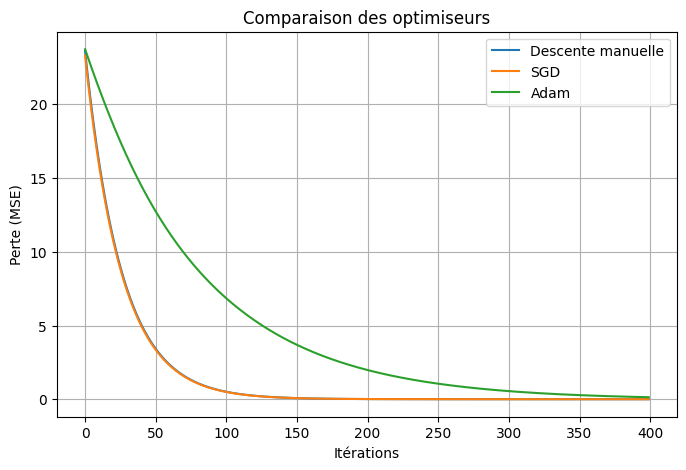

In [1]:
# Question 1
import torch
from torch import nn
import matplotlib.pyplot as plt

# Données synthétiques
torch.manual_seed(7)
n, d = 2000, 10
X = torch.randn(n, d)
w_true = torch.randn(d, 1) * 2.0
b_true = torch.randn(1) * 0.5
y = X @ w_true + b_true + 0.1 * torch.randn(n, 1)

# Descente de gradient manuelle
def entrainer_manuel(lr=0.05, nb_iter=400):
    w = nn.Parameter(torch.randn(d, 1)*0.1)
    b = nn.Parameter(torch.zeros(1))
    pertes = []
    for t in range(nb_iter):
        y_hat = X @ w + b
        perte = ((y_hat - y)**2).mean()
        perte.backward()
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
            w.grad.zero_()
            b.grad.zero_()
        pertes.append(perte.item())
        if (t+1) % 50 == 0:
            print(f"[manuel] it={t+1:04d} perte={perte.item():.6f}")
    return pertes, w.detach(), b.detach()

# Avec optimiseur SGD
def entrainer_sgd(lr=0.05, nb_iter=400):
    w = nn.Parameter(torch.randn(d, 1)*0.1)
    b = nn.Parameter(torch.zeros(1))
    optim = torch.optim.SGD([w, b], lr=lr)
    pertes = []
    for t in range(nb_iter):
        y_hat = X @ w + b
        perte = ((y_hat - y)**2).mean()
        optim.zero_grad()
        perte.backward()
        optim.step()
        pertes.append(perte.item())
        if (t+1) % 50 == 0:
            print(f"[SGD] it={t+1:04d} perte={perte.item():.6f}")
    return pertes, w.detach(), b.detach()


# Avec optimiseur Adam
def entrainer_adam(lr=0.05, nb_iter=400):
    w = nn.Parameter(torch.randn(d, 1)*0.1)
    b = nn.Parameter(torch.zeros(1))
    optim = torch.optim.Adam([w, b], lr=lr)
    pertes = []
    for t in range(nb_iter):
        y_hat = X @ w + b
        perte = ((y_hat - y)**2).mean()
        optim.zero_grad()
        perte.backward()
        optim.step()
        pertes.append(perte.item())
        if (t+1) % 50 == 0:
            print(f"[Adam] it={t+1:04d} perte={perte.item():.6f}")
    return pertes, w.detach(), b.detach()

# Exécution et comparaison
pertes_man, w_m, b_m = entrainer_manuel(lr=0.01, nb_iter=400)
pertes_sgd, w_s, b_s = entrainer_sgd(lr=0.01, nb_iter=400)
pertes_adam, w_a, b_a = entrainer_adam(lr=0.01, nb_iter=400)


# Visualisation
plt.figure(figsize=(8,5))
plt.plot(pertes_man, label='Descente manuelle')
plt.plot(pertes_sgd, label='SGD')
plt.plot(pertes_adam, label='Adam')
plt.xlabel('Itérations')
plt.ylabel('Perte (MSE)')
plt.title('Comparaison des optimiseurs')
plt.legend()
plt.grid(True)
plt.show()

In [2]:
# Question 2
import torch
import torch.nn as nn
import torch.optim as optim

# Version 1 — Classe personnalisée
class MonReseau(nn.Module):
    def __init__(self):
        super(MonReseau, self).__init__()
        self.fc1 = nn.Linear(10, 100)  # couche linéaire 1
        self.act = nn.Tanh()           # fonction d’activation
        self.fc2 = nn.Linear(100, 1)   # couche linéaire 2 (sortie)
    def forward(self, x):
        x = self.act(self.fc1(x))
        x = self.fc2(x)
        return x

# création du modèle
modele1 = MonReseau()
critere = nn.MSELoss()
optimiseur = optim.SGD(modele1.parameters(), lr=0.01)

# données synthétiques
X = torch.randn(200, 10)
Y = torch.randn(200, 1)

# boucle d’entraînement
for epoch in range(50):
    optimiseur.zero_grad()
    sortie = modele1(X)
    perte = critere(sortie, Y)
    perte.backward()
    optimiseur.step()
    if epoch % 10 == 0:
        print(f"[Classe] Époque {epoch:02d} — Perte = {perte.item():.4f}")

# Version 2 — nn.Sequential
modele2 = nn.Sequential(
    nn.Linear(10, 100),
    nn.Tanh(),
    nn.Linear(100, 1)
)
critere2 = nn.MSELoss()
optimiseur2 = optim.SGD(modele2.parameters(), lr=0.01)

for epoch in range(50):
    optimiseur2.zero_grad()
    sortie2 = modele2(X)
    perte2 = critere2(sortie2, Y)
    perte2.backward()
    optimiseur2.step()
    if epoch % 10 == 0:
        print(f"[Sequential] Époque {epoch:02d} — Perte = {perte2.item():.4f}")


[Classe] Époque 00 — Perte = 1.0799
[Classe] Époque 10 — Perte = 0.9731
[Classe] Époque 20 — Perte = 0.9362
[Classe] Époque 30 — Perte = 0.9218
[Classe] Époque 40 — Perte = 0.9154
[Sequential] Époque 00 — Perte = 1.1075
[Sequential] Époque 10 — Perte = 0.9966
[Sequential] Époque 20 — Perte = 0.9539
[Sequential] Époque 30 — Perte = 0.9351
[Sequential] Époque 40 — Perte = 0.9257


In [9]:
# Question 3 
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.datasets import fetch_openml

# Charger MNIST 
X, y = fetch_openml('mnist_784', return_X_y=True, as_frame=False)
X = torch.tensor(X / 255.0, dtype=torch.float32)   # normaliser entre 0 et 1
y = torch.tensor(y.astype(int), dtype=torch.long)  

# Définir un Dataset personnalisé
class MonDataset(Dataset):
    def __init__(self, X, y):
        self.X, self.y = X, y
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Créer le dataset 
data = MonDataset(X, y)

# Tester plusieurs tailles de batch
for taille in [16, 64, 256]:
    loader = DataLoader(data, batch_size=taille, shuffle=True)
    images, labels = next(iter(loader))
    print(f"\nBatch size = {taille}")
    print("Images:", images.shape)
    print("Labels:", labels.shape)




Batch size = 16
Images: torch.Size([16, 784])
Labels: torch.Size([16])

Batch size = 64
Images: torch.Size([64, 784])
Labels: torch.Size([64])

Batch size = 256
Images: torch.Size([256, 784])
Labels: torch.Size([256])


In [4]:
# Question 4
import torch
import torch.nn as nn


class AutoEncodeur(nn.Module):
    def __init__(self, dim_in=784, dim_latent=64):
        super(AutoEncodeur, self).__init__()
        # encodage : linéaire → ReLU
        self.encodeur = nn.Sequential(
            nn.Linear(dim_in, dim_latent),
            nn.ReLU()
        )
        # Partie décodage : linéaire → Sigmoid
        self.decodeur = nn.Sequential(
            nn.Linear(dim_latent, dim_in),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encodeur(x)   # compression
        x_reconstruit = self.decodeur(z)  # reconstruction
        return x_reconstruit


# ==== Test ====
X = torch.randn(5, 784) 
modele = AutoEncodeur()
out = modele(X)

print("Entrée :", X.shape)
print("Sortie :", out.shape)


Entrée : torch.Size([5, 784])
Sortie : torch.Size([5, 784])


In [1]:
# Question 5
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torch.utils.tensorboard import SummaryWriter

# Préparation des données MNIST 
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1))  
])
train = datasets.MNIST("./data", train=True, download=True, transform=transform)
loader = DataLoader(train, batch_size=256, shuffle=True)

# autoencodeur 
class Autoencodeur(nn.Module):
    def __init__(self, dim_in=784, dim_latent=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(dim_in, 256), 
            nn.ReLU(),
            nn.Linear(256, dim_latent)
        )
        self.decoder = nn.Sequential(
            nn.Linear(dim_latent, 256), 
            nn.ReLU(),
            nn.Linear(256, dim_in), nn.Sigmoid()
        )
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

# Initialisation
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Autoencodeur().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
crit = nn.MSELoss()
writer = SummaryWriter("runs/autoencoder_MNIST")

# Entraînement
for epoch in range(5):
    total = 0
    for x, _ in loader:
        x = x.to(device)
        opt.zero_grad()
        x_rec, z = model(x)
        loss = crit(x_rec, x)
        loss.backward()
        opt.step()
        total += loss.item()
    print(f"Époque {epoch+1}/5 — Perte: {total/len(loader):.6f}")
    writer.add_scalar("Perte/train", total/len(loader), epoch)

    # Checkpoint
    torch.save(model.state_dict(), f"checkpoint_epoch{epoch+1}.pt")

    # Échantillons d’images originales et reconstruites
    images_in = x[:8].view(-1, 1, 28, 28)
    images_out = x_rec[:8].view(-1, 1, 28, 28)
    writer.add_images("Originales", images_in, epoch)
    writer.add_images("Reconstructions", images_out, epoch)

# Sélection de deux exemples de classes différentes
x1, _ = train[0]; x2, _ = train[1]
x1, x2 = x1.to(device), x2.to(device)
z1 = model.encoder(x1)
z2 = model.encoder(x2)
# Interpolation linéaire entre z1 et z2
imgs = []
for λ in torch.linspace(0, 1, steps=8):
    z = λ * z1 + (1 - λ) * z2
    rec = model.decoder(z)
    imgs.append(rec.view(1, 1, 28, 28))
writer.add_images("Interpolation_latente", torch.cat(imgs), 0)

writer.close()
print("Entraînement terminé. Lancez TensorBoard pour visualiser")

Époque 1/5 — Perte: 0.055382
Époque 2/5 — Perte: 0.021922
Époque 3/5 — Perte: 0.015014
Époque 4/5 — Perte: 0.012278
Époque 5/5 — Perte: 0.010737
Entraînement terminé. Lancez TensorBoard pour visualiser


In [2]:
!tensorboard --logdir runs

TensorFlow installation not found - running with reduced feature set.
Serving TensorBoard on localhost; to expose to the network, use a proxy or pass --bind_all
TensorBoard 2.20.0 at http://localhost:6007/ (Press CTRL+C to quit)
^C


Époque 1 — Highway: 0.3796 | MLP: 0.3928
Époque 2 — Highway: 0.1485 | MLP: 0.1669
Époque 3 — Highway: 0.1036 | MLP: 0.1134
Époque 4 — Highway: 0.0770 | MLP: 0.0828
Époque 5 — Highway: 0.0599 | MLP: 0.0654
Époque 6 — Highway: 0.0494 | MLP: 0.0522
Époque 7 — Highway: 0.0396 | MLP: 0.0436
Époque 8 — Highway: 0.0333 | MLP: 0.0349
Époque 9 — Highway: 0.0282 | MLP: 0.0273
Époque 10 — Highway: 0.0250 | MLP: 0.0239


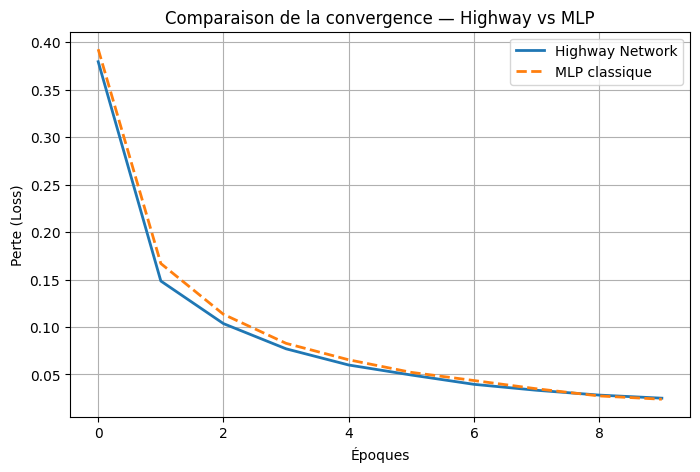

In [3]:
# Question 6
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader



class HighwayLayer(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.H = nn.Linear(dim, dim)       # transformation principale
        self.T = nn.Linear(dim, dim)       # porte 
        self.bias_init()

    def bias_init(self):
        self.T.bias.data.fill_(-1)

    def forward(self, x):
        H_out = F.relu(self.H(x))          # H(x)
        T_out = torch.sigmoid(self.T(x))   # T(x)
        return H_out * T_out + x * (1 - T_out)  # y = H*T + x*(1-T)

# Réseau complet pour MNIST 
class HighwayNet(nn.Module):
    def __init__(self, dim_in=784, dim_hidden=128, num_layers=3, dim_out=10):
        super().__init__()
        self.fc_in = nn.Linear(dim_in, dim_hidden)
        self.highways = nn.ModuleList([HighwayLayer(dim_hidden) for _ in range(num_layers)])
        self.fc_out = nn.Linear(dim_hidden, dim_out)

    def forward(self, x):
        x = F.relu(self.fc_in(x))
        for h in self.highways:
            x = h(x)                       # passage par les couches highway
        return self.fc_out(x)

# Entraînement et comparaison
# Préparation des données MNIST
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1))
])
train = datasets.MNIST("./data", train=True, download=True, transform=transform)
test = datasets.MNIST("./data", train=False, transform=transform)
train_loader = DataLoader(train, batch_size=128, shuffle=True)
test_loader = DataLoader(test, batch_size=256)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Modèles à comparer
model_highway = HighwayNet().to(device)
model_mlp = nn.Sequential(
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

# Fonction de perte et optimiseur
criterion = nn.CrossEntropyLoss()
opt_h = torch.optim.Adam(model_highway.parameters(), lr=1e-3)
opt_m = torch.optim.Adam(model_mlp.parameters(), lr=1e-3)

# Boucle d'entraînement
def train_epoch(model, opt):
    model.train()
    total_loss = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        opt.step()
        total_loss += loss.item()
    return total_loss / len(train_loader)

# Entraînement
epochs = 10
loss_highway, loss_mlp = [], []

for epoch in range(epochs):
    l1 = train_epoch(model_highway, opt_h)
    l2 = train_epoch(model_mlp, opt_m)
    loss_highway.append(l1)
    loss_mlp.append(l2)
    print(f"Époque {epoch+1} — Highway: {l1:.4f} | MLP: {l2:.4f}")

# Visualisation : courbes de perte
plt.figure(figsize=(8,5))
plt.plot(loss_highway, label="Highway Network", linewidth=2)
plt.plot(loss_mlp, label="MLP classique", linestyle="--", linewidth=2)
plt.xlabel("Époques")
plt.ylabel("Perte (Loss)")
plt.title("Comparaison de la convergence — Highway vs MLP")
plt.legend()
plt.grid(True)
plt.show()